# Lösung L31 - Schaetzung des Leistungsdichtespektrums nach Blackman-Tuckey

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l31.m).

Weitere benötigne MATLAB `*.m`-Dateien:  [`lblack.m`](./lblack.m) und darin: [`lrader.m`](./lrader.m)

```matlab
% ##################################################################################
% ## Funktion: lrader.m ; AKF-Schaetzung mit Raderverfahren                       ##
% ##################################################################################
%
%  function rxx  = lrader(M,x) 
%
%  Nicht erwartungstreue AKF-Schaetzung nach dem Rader-Verfahren.
%  Der Parameter M muss eine Zweierpotenz sein und entspricht dem 
%  (Maximalwert+1) fuer lambda. Der Vektor x mit den Signalwerten  
%  darf eine beliebige Dimension annehmen und kann als Spalten- oder
%  Zeilenvektor uebergeben werden. Die Ausgabe erfolgt als Spalten-
%  vektor der Dimension M sowie nur fuer positive lambda-Werte:
%  rxx = [rxx(0), ..., rxx(M-1)].
%  Fuer negative lambda ist eine konj. gerade Ergaenzung vorzunehmen.

function rxx  = lrader(M,x)
x = x(:);                            % Spaltenvektoren erzeugen
N = length(x);
u = zeros(2*M,1);
u(1:M) = x(1:M);
U = fft(u);
K = floor(N/M);
v = zeros(2*M,1);
Sxx = zeros(2*M,1);
pm = (-1).^(0:(2*M-1)).';

for ii = 1:(K-1)                     % Iteration und Akkumulation
  v(1:M) = x((ii*M+1):((ii+1)*M));
  V = fft(v);
  Sxx = Sxx + (conj(U) .*(U + (pm .*V)));
  U = V;
end
if K < N/M
  b = N - K*M;
  v = zeros(2*M,1);
  v(1:b) = x((K*M+1):N);
  V = fft(v);
  Sxx = Sxx + (conj(U) .*(U + (pm .*V)));
end
Sxx = Sxx + abs(V.^2);
rxx = ifft(Sxx)/N;
rxx = rxx(1:M);
end
% #####  EOF  #####
```

```Matlab
% ##################################################################################
% ##  Funktion: lblack.m; Berechnung des Blackman-Tuckey-Leistungsdichtespektrums ##
% ##  --------------------------------------------------------------------------  ##
% ##  Benoetigte(s) m-File(s):  lrader.m                                          ##
% ##################################################################################
%
% function Sxx = lblack(x,M,windowtype[,NFFT]);
%
% Schaetzung der spektralen Leistungsdichte nach Blackman-Tukey (1958)
%   x           Datenfolge (Zeilen- oder Spaltenvektor)
%   M           Anzahl der verwendeten Autokorrelationswerte
%               (sollte Zweierpotenz sein):  rxx(-(M-1)), ..., rxx(M-1)
%   windowtype  Fensterfunktion (String, z.B. 'hamming'),
%  [NFFT]       FFT-Laenge (optional)

function Sxx = lblack(x,M,windowtype,NFFT)

rxx = lrader(M,x);                  % rxx = [rxx(0); ...; rxx(M-1)]
rxx = [flipud(conj(rxx(2:M))); rxx];  % Konj. gerade Ergaenzung
% => Laenge 2M-1
eval(['fenster= ', windowtype,'(2*M-1);']); % Fensterfunktion der Laenge
if nargin<4
        NFFT=nextpow2(length(x));
end % 2M-1 berechnen
Sxx = abs(fft(rxx.*(fenster),NFFT));
% #####  EOF  #####
```

This exercise is part of the book [[KK22]](https://doi.org/10.1007/978-3-663-09805-8) for which the respective exercises can be downloaded [here](https://www.comm.uni-bremen.de/en/books/dsv/).

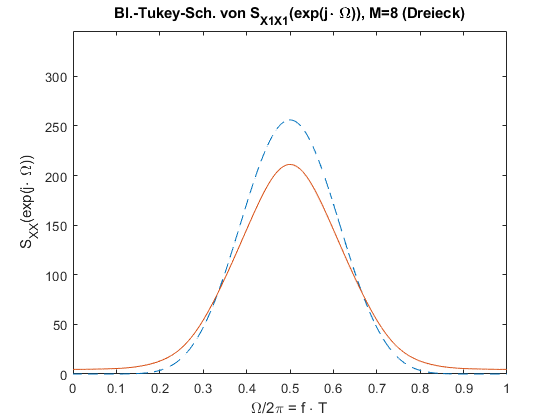

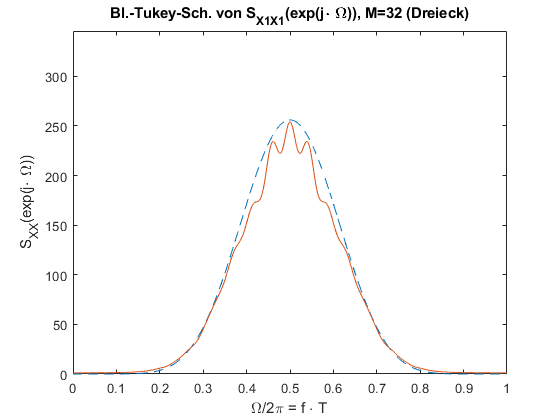

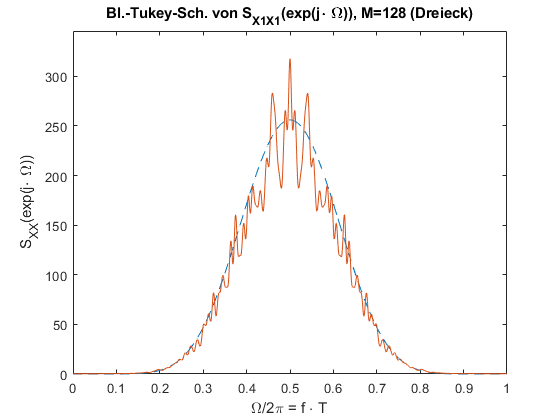

In [4]:
% Modellrauschprozesse
N     = 2^12;           % Anzahl der Abtastwerte um das System in den eingeschw.
N_vor = 500;            % Zustand zu setzen

n  = randn(1,N+N_vor);  

h1 = [1 -4 6 -4 +1]; x1_all = filter(h1,1,n); x1=x1_all(N_vor+1:length(x1_all));
h2 = [1 0.8];        x2_all = filter(1,h2,n); x2=x2_all(N_vor+1:length(x2_all));

% "Wahres" Leistungsdichtespektrum zum Vergleich berechnen
NFFT = 2^12;  
Sx1x1 = abs(fft(h1,NFFT)).^2;                axis_Sx1=[0 1 0 1.35*max(Sx1x1)];
Sx2x2 = ones(1,NFFT)./abs(fft(h2,NFFT)).^2;  axis_Sx2=[0 1 0 1.35*max(Sx2x2)];
fT = 0:1/NFFT:1-1/NFFT;

% Schaetzung des Leistungsdichtespektrums fuer M=8, 32, 128
win = 'triang';

Sxx_x1_8   = lblack(x1,8,win,NFFT);
Sxx_x1_32  = lblack(x1,32,win,NFFT); 
Sxx_x1_128 = lblack(x1,128,win,NFFT);

Sxx_x2_8   = lblack(x2,8,win,NFFT);
Sxx_x2_32  = lblack(x2,32,win,NFFT); 
Sxx_x2_128 = lblack(x2,128,win,NFFT); 

% # grafische Ausgabe # %
figure;
plot(fT,Sx1x1,'--'); 
hold on;  
plot(fT,Sxx_x1_8); 
xlabel('\Omega/2\pi = f \cdot T'); 
ylabel('S_{XX}(exp(j\cdot \Omega))');
title('Bl.-Tukey-Sch. von S_{X1X1}(exp(j\cdot \Omega)), M=8 (Dreieck)');
axis(axis_Sx1);  

figure;   
plot(fT,Sx1x1,'--'); 
hold on;  
plot(fT,Sxx_x1_32); 
xlabel('\Omega/2\pi = f \cdot T'); 
ylabel('S_{XX}(exp(j\cdot \Omega))');
title('Bl.-Tukey-Sch. von S_{X1X1}(exp(j\cdot \Omega)), M=32 (Dreieck)'); 
axis(axis_Sx1); 

figure;  
plot(fT,Sx1x1,'--');
hold on; 
plot(fT,Sxx_x1_128);
xlabel('\Omega/2\pi = f \cdot T'); 
ylabel('S_{XX}(exp(j\cdot \Omega))');
title('Bl.-Tukey-Sch. von S_{X1X1}(exp(j\cdot \Omega)), M=128 (Dreieck)'); 
axis(axis_Sx1); 

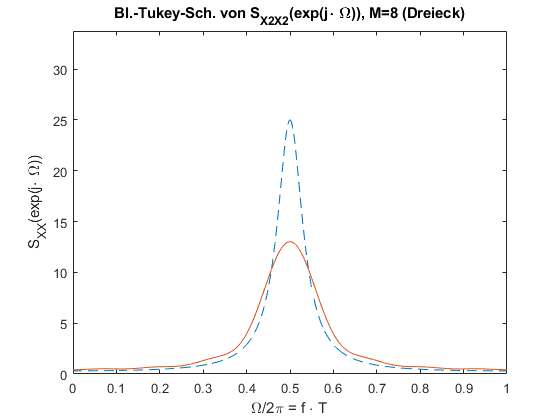

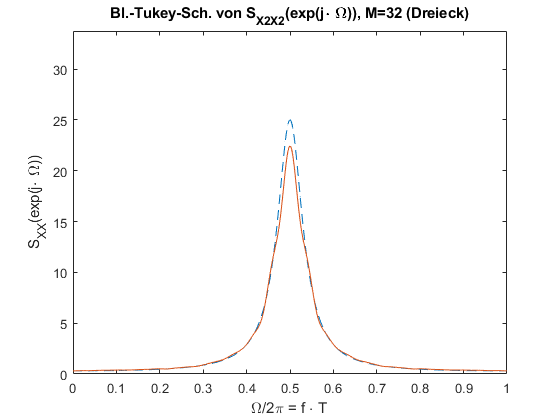

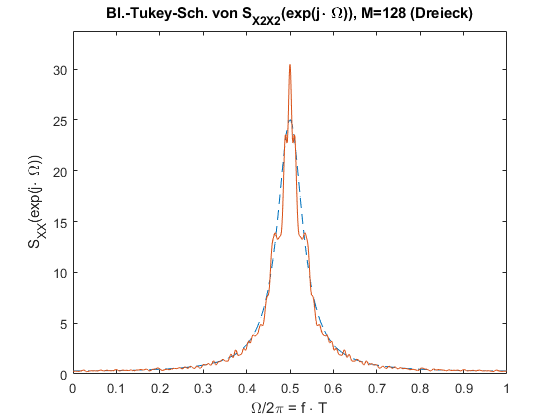

In [5]:
figure;   
plot(fT,Sx2x2,'--'); 
hold on;  
plot(fT,Sxx_x2_8); 
xlabel('\Omega/2\pi = f \cdot T'); 
ylabel('S_{XX}(exp(j\cdot \Omega))');
title('Bl.-Tukey-Sch. von S_{X2X2}(exp(j\cdot \Omega)), M=8 (Dreieck)');
axis(axis_Sx2);  

figure;
plot(fT,Sx2x2,'--'); 
hold on; 
plot(fT,Sxx_x2_32); 
xlabel('\Omega/2\pi = f \cdot T'); 
ylabel('S_{XX}(exp(j\cdot \Omega))');
title('Bl.-Tukey-Sch. von S_{X2X2}(exp(j\cdot \Omega)), M=32 (Dreieck)'); 
axis(axis_Sx2); 

figure;  
plot(fT,Sx2x2,'--');
hold on; 
plot(fT,Sxx_x2_128); 
xlabel('\Omega/2\pi = f \cdot T'); 
ylabel('S_{XX}(exp(j\cdot \Omega))');
title('Bl.-Tukey-Sch. von S_{X2X2}(exp(j\cdot \Omega)), M=128 (Dreieck)'); 
axis(axis_Sx2); 

# Referenzen

[[KK22]](https://doi.org/10.1007/978-3-663-09805-8) K.-D. Kammeyer, K. Kroschel: "Digitale Signalverarbeitung - Filterung und Spektralanalyse", Springer Vieweg, 2022. Exercises can be downloaded [here](https://www.comm.uni-bremen.de/en/publications/dsv/).